# MCMC example

Fit `vsini`, `vmacro` and the thermal width `sigma_th` to lines A–D with `emcee`. All four lines are consistent here.
The true values are 100, 10 and 15 km/s.

In this toy model the thermal and macroturbulent broadening are both Gaussian, so the data only constrain
`σ_tot = √(σ_th² + v_macro²)`. Real kernels are not both Gaussian, but near-degeneracies like this are common, and
curvature errors break down on them.

The `wellfit` likelihood is `wf.log_likelihood(residuals, err_obs_scaled, n_corr, sigma_sys)` = −χ²_eff/2 + const. We
compare it with the naive likelihood (`err_obs`, independent pixels, no floor).

In [1]:
import sys
sys.path.insert(0, '..')   # or install the package: pip install -e ..
import numpy as np
import matplotlib.pyplot as plt
import emcee, corner
import wellfit as wf
import toy_lines as tl
from scipy.optimize import minimize
%matplotlib inline

## 1. Data

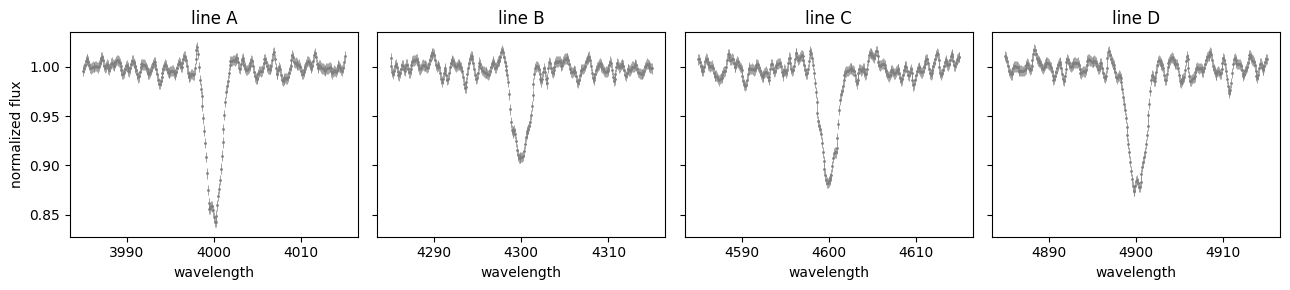

In [2]:
# Select a set of "true" parameters for the synthetic data (all four lines consistent: line D has the same v sin i)
TRUTH = dict(vsini=100., vmacro=10., sigma_th=15.)

# Generate synthetic data with the above parameters
d = tl.make_data(vsini=TRUTH['vsini'], vmacro=TRUTH['vmacro'], sigma_th=TRUTH['sigma_th'],
                 vsini_D=TRUTH['vsini'], snr=150.)
lam_obs, flux_obs, err_obs, groups, names = d['lam'], d['flux'], d['err'], d['groups'], d['names']

# Plot the synthetic data
fig, axs = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for j, ax in enumerate(axs):
    m = groups == j
    ax.errorbar(lam_obs[m], flux_obs[m], err_obs[m], fmt='.', ms=2, color='0.5', lw=0.5)
    ax.set_title(f'line {names[j]}'); ax.set_xlabel('wavelength')
axs[0].set_ylabel('normalized flux'); plt.tight_layout()

## 2. Noise

Both quantities are measured in the line-free continuum next to each line (`d['ref_ranges']`), with a constant
baseline (`deg=0`).

- `measure_error_scale`: the factor that brings the continuum scatter to unit width (expected ≈ 1.25).
- `measure_n_corr`: the number of correlated pixels (expected ≈ 5). Short continuum segments bias it slightly low.

error scale factor = 1.26   (injected 1 / 0.8 = 1.25)


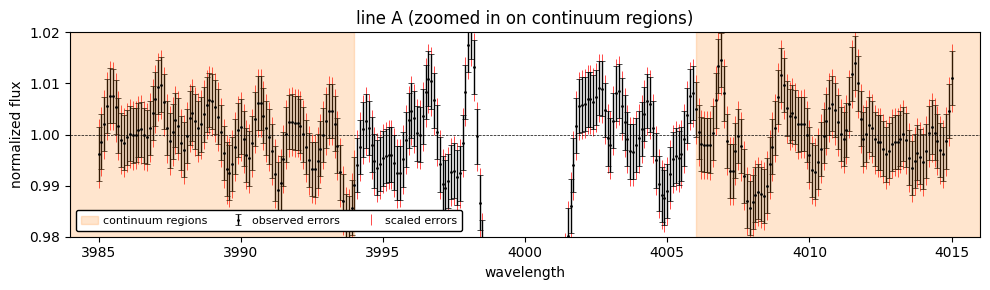

In [3]:
# Measure the error scale factor (i.e., how much the observed errors need to be scaled to match the actual scatter)
err_obs_scaled, factor = wf.measure_error_scale(lam_obs, flux_obs, err_obs, d['ref_ranges'], deg=0)
print(f"error scale factor = {factor:.2f}   (injected 1 / 0.8 = 1.25)")

# Plot the measured error scale factor for one of the lines, zoomed in on continuum regions
fig, ax = plt.subplots(1, 1, figsize=(10, 3))
m = groups == 0
ax.errorbar(lam_obs[m], flux_obs[m], err_obs[m], fmt='.', ms=2, color='k', lw=1, zorder=1, capthick=0.5, capsize=2, label='observed errors')
# Scale the errors by the measured factor to show that the scatter is now consistent with the errors
ax.errorbar(lam_obs[m], flux_obs[m], err_obs[m] * factor, fmt='None', ms=2, color='red', lw=0.5, zorder=0, label='scaled errors')
ax.set_title(f'line {names[0]} (zoomed in on continuum regions)'); ax.set_xlabel('wavelength'); ax.set_ylabel('normalized flux')
for j in range(2):
    ax.axvspan(d['ref_ranges'][j][0], d['ref_ranges'][j][1], color='C1', alpha=0.2, label='continuum regions' if j == 0 else None)
ax.set_xlim(d['ref_ranges'][0][0], d['ref_ranges'][1][1]); plt.tight_layout()
ax.axhline(1, color='k', ls='--', lw=0.5)
ax.set_ylim(0.98, 1.02)
ax.legend(loc='lower left', fontsize=8, frameon=True, 
          framealpha=1, fancybox=True, edgecolor='k', facecolor='w', handlelength=1.5, handletextpad=0.5, borderpad=0.5, ncol=3)
plt.tight_layout()

In [4]:
# Measure the number of correlated pixels and the correlation coefficients
n_corr, rho = wf.measure_n_corr(lam_obs, flux_obs, err_obs, d['ref_ranges'], deg=0)
print(f"n_corr = {n_corr:.2f}   (injected {d['truth']['n_corr']:.2f}); rho_1..4 = {np.round(rho[:4], 2)}")
print(f"{lam_obs.size} pixels -> {lam_obs.size / n_corr:.0f} independent pixels")

n_corr = 4.94   (injected 5.32); rho_1..4 = [0.88 0.62 0.34 0.13]
1204 pixels -> 244 independent pixels


## 3. Best fit and systematic floor

`fit_optimizer` provides `sigma_sys` and a starting point. Its curvature errors on `vmacro` and `sigma_th` are
meaningless, because `χ²_eff` is nearly flat along the degeneracy.

In [5]:
PARAMS = ['vsini', 'vmacro', 'sigma_th']

def residuals(theta):
    return tl.model(lam_obs, groups, *theta) - flux_obs

def nelder_mead(objective, theta_start):
    return minimize(objective, theta_start, method='Nelder-Mead', bounds=[(0, 400)] * len(theta_start),
                    options={'xatol': 1e-3, 'fatol': 1e-6, 'maxiter': 5000}).x

fit = wf.fit_optimizer(residuals, nelder_mead, [80., 20., 20.], err_obs_scaled, n_corr, param_names=PARAMS)
print(fit.summary())

n_data = 1204, n_corr = 4.94 -> 243.8 independent points, nu = 240.8
sigma_sys = 0.001937; best fit: chi2 = 1288.0 (raw), chi2_eff = 240.8
Parameters (value +stat -stat, +sys -sys):
  vsini           99.04  +2.772 -2.772   sys +0 -0
  vmacro          21.95  +423.3 -423.3   sys +0 -0
  sigma_th        1.515  +6132 -6132   sys +0 -0


## 4. Sampling

The priors are flat: 0–300 km/s for `vsini`, and 0–100 km/s for `vmacro` and `sigma_th`. `sigma_sys` is fixed at the
optimizer's value. It can also be sampled, since `log_likelihood` includes the normalization term that requires.

In [6]:
LO, HI = np.zeros(3), np.array([300., 100., 100.])

def log_prior(theta):
    return 0. if np.all((theta >= LO) & (theta <= HI)) else -np.inf

def log_post_wellfit(theta, prior=log_prior):
    lp = prior(theta)
    return lp + wf.log_likelihood(residuals(theta), err_obs_scaled, n_corr, fit.sigma_sys) if np.isfinite(lp) else -np.inf

def log_post_naive(theta):
    lp = log_prior(theta)
    return lp + wf.log_likelihood(residuals(theta), err_obs, 1., 0.) if np.isfinite(lp) else -np.inf

N_WALKERS, N_STEPS, BURN = 32, 4000, 1000

def run(log_post, seed=0):
    np.random.seed(seed)                  # emcee draws from numpy's global state: seed it for reproducible chains
    rng = np.random.default_rng(seed)
    p0 = np.abs(fit.theta + 0.5 * rng.normal(size=(N_WALKERS, 3)))
    sampler = emcee.EnsembleSampler(N_WALKERS, 3, log_post)
    sampler.run_mcmc(p0, N_STEPS)
    tau = sampler.get_autocorr_time(tol=0)
    print(f"acceptance {sampler.acceptance_fraction.mean():.2f}; autocorrelation times {np.round(tau)} steps "
          f"(chain = {N_STEPS / tau.max():.0f} x the longest)")
    return sampler.get_chain(discard=BURN, thin=10, flat=True)

chain_naive = run(log_post_naive)
chain_wf = run(log_post_wellfit)

acceptance 0.47; autocorrelation times [ 54. 136. 132.] steps (chain = 29 x the longest)


acceptance 0.56; autocorrelation times [44. 64. 69.] steps (chain = 58 x the longest)


In [7]:
def summarize(chain, label):
    q = np.percentile(chain, [16, 50, 84], axis=0)
    tot = np.percentile(np.hypot(chain[:, 1], chain[:, 2]), [16, 50, 84])
    cols = [f"{k} = {q[1, i]:5.1f} +{q[2, i] - q[1, i]:4.1f} -{q[1, i] - q[0, i]:4.1f}" for i, k in enumerate(PARAMS)]
    cols.append(f"sigma_tot = {tot[1]:4.1f} +{tot[2] - tot[1]:3.1f} -{tot[1] - tot[0]:3.1f}")
    print(f"{label:22s}" + "   ".join(cols))

summarize(chain_naive, 'naive')
summarize(chain_wf, 'wellfit')
print(f"{'truth':22s}" + "   ".join(f"{k} = {TRUTH[k]:5.1f}" for k in PARAMS)
      + f"   sigma_tot = {np.hypot(TRUTH['vmacro'], TRUTH['sigma_th']):4.1f}")

naive                 vsini =  98.9 + 0.9 - 1.0   vmacro =  15.7 + 5.6 -10.2   sigma_th =  15.6 + 5.7 -10.0   sigma_tot = 22.1 +1.3 -1.2
wellfit               vsini =  98.5 + 2.7 - 3.1   vmacro =  15.5 + 7.0 - 9.9   sigma_th =  15.5 + 6.8 -10.1   sigma_tot = 22.9 +3.8 -3.6
truth                 vsini = 100.0   vmacro =  10.0   sigma_th =  15.0   sigma_tot = 18.0


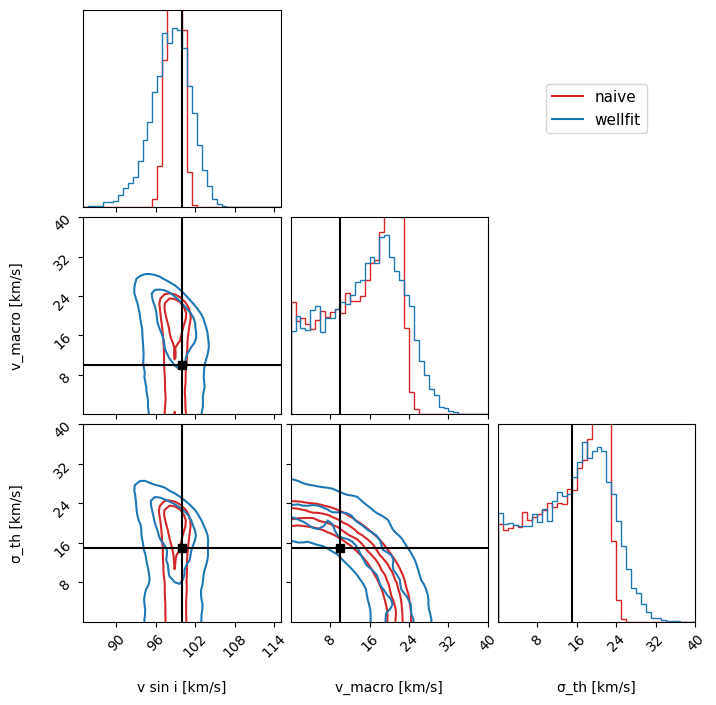

In [8]:
RANGE = [(85, 115), (0, 40), (0, 40)]
LABELS = ['v sin i [km/s]', 'v_macro [km/s]', 'σ_th [km/s]']
TRUTHS = [TRUTH[k] for k in PARAMS]
kw = dict(range=RANGE, labels=LABELS, bins=40, smooth=1.0, levels=[0.393, 0.865], plot_datapoints=False,
          plot_density=False, fill_contours=False)   # levels: 1 and 2 sigma in 2D
fig = corner.corner(chain_naive, color='C3', **kw)
corner.corner(chain_wf, fig=fig, color='C0', truths=TRUTHS, truth_color='k', **kw)
fig.axes[2].plot([], [], 'C3', label='naive'); fig.axes[2].plot([], [], 'C0', label='wellfit')
fig.axes[2].legend(loc='center', fontsize=11)
fig.set_size_inches(7.5, 7.5)

The `vmacro`–`sigma_th` degeneracy shows as an arc, σ_th² + v_macro² ≈ const, which curvature errors cannot describe.

The naive arc is much thinner. Naive `σ_tot` = 22.1 ± 1.3 km/s is about 3σ from the true 18.0, while `wellfit` gives
22.9 ± 4, within about 1σ. The naive `vsini` error (±1 km/s) is likewise about 3× too small.

## 5. Combined width

`σ_tot` is constrained, even though `σ_th` and `v_macro` are not separately.

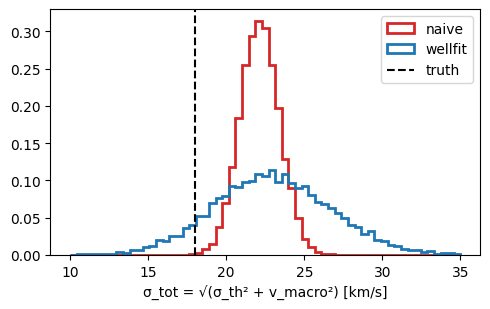

In [9]:
fig, ax = plt.subplots(figsize=(5, 3.2))
bins = np.linspace(10, 35, 60)
for ch, col, lab in [(chain_naive, 'C3', 'naive'), (chain_wf, 'C0', 'wellfit')]:
    ax.hist(np.hypot(ch[:, 1], ch[:, 2]), bins, density=True, histtype='step', color=col, lw=2, label=lab)
ax.axvline(np.hypot(TRUTH['vmacro'], TRUTH['sigma_th']), color='k', ls='--', label='truth')
ax.set_xlabel('σ_tot = √(σ_th² + v_macro²) [km/s]'); ax.legend(); plt.tight_layout()

## 6. Prior on the thermal width

If `σ_th` is known independently, for example from a temperature, add it as a prior. Here we use σ_th = 14 ± 2 km/s,
deliberately off the truth. It narrows `vmacro` and removes the pile-up at `vmacro = 0`.

acceptance 0.64; autocorrelation times [40. 41. 37.] steps (chain = 99 x the longest)
wellfit, flat priors  vsini =  98.5 + 2.7 - 3.1   vmacro =  15.5 + 7.0 - 9.9   sigma_th =  15.5 + 6.8 -10.1   sigma_tot = 22.9 +3.8 -3.6
wellfit, σ_th prior   vsini =  99.1 + 2.7 - 3.1   vmacro =  16.4 + 5.1 - 6.6   sigma_th =  14.2 + 2.0 - 1.9   sigma_tot = 21.8 +3.8 -3.9


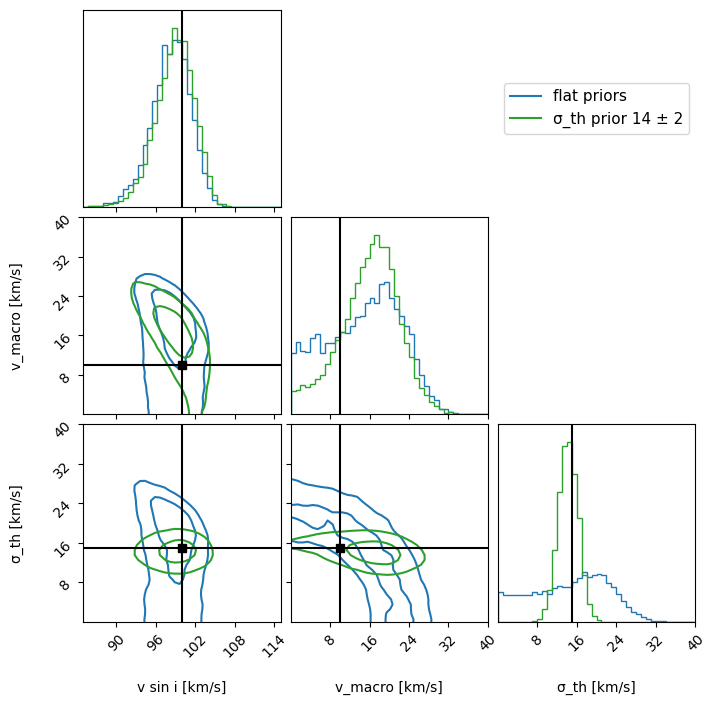

In [10]:
def log_prior_thermal(theta, mu=14., sd=2.):
    lp = log_prior(theta)
    return lp - 0.5 * ((theta[2] - mu) / sd)**2 if np.isfinite(lp) else -np.inf

chain_prior = run(lambda th: log_post_wellfit(th, prior=log_prior_thermal))
summarize(chain_wf, 'wellfit, flat priors')
summarize(chain_prior, 'wellfit, σ_th prior')

fig = corner.corner(chain_wf, color='C0', **kw)
corner.corner(chain_prior, fig=fig, color='C2', truths=TRUTHS, truth_color='k', **kw)
fig.axes[2].plot([], [], 'C0', label='flat priors'); fig.axes[2].plot([], [], 'C2', label='σ_th prior 14 ± 2')
fig.axes[2].legend(loc='center', fontsize=11)
fig.set_size_inches(7.5, 7.5)

## Summary

- Use `wf.log_likelihood` with `err_obs_scaled`, `n_corr` and `sigma_sys` from `fit_optimizer` or `fit_grid`. The naive
  likelihood is about `√n_corr` too narrow and can exclude the truth.
- For degenerate parameters, report the constrained combination or add a prior. Curvature errors are not meaningful
  there.
- Check convergence: each chain should span many autocorrelation times.